# 03 — Interpretasi Model (SHAP) dan Rekomendasi Bisnis

Notebook ini menjelaskan **mengapa** model memberi skor risiko tertentu, secara global (seluruh data test) dan lokal (per pelanggan).

**Cara membaca SHAP:**
- Nilai SHAP adalah kontribusi satu fitur terhadap skor model dalam satuan *log-odds*. Positif berarti menaikkan risiko churn, negatif berarti menurunkannya.
- Skor akhir = nilai dasar (rata-rata model) + jumlah semua nilai SHAP. Sifat aditif ini dicek di sel pertama.
- Kolom one-hot (misalnya `Contract_One year`, `Contract_Two year`) dijumlahkan kembali menjadi satu fitur `Contract`. Ini sah karena SHAP aditif.
- **SHAP menjelaskan model, bukan dunia nyata.** Fitur yang menaikkan skor risiko *berhubungan* dengan churn di data ini, belum tentu *menyebabkan* churn.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import warnings
warnings.filterwarnings("ignore")

import joblib
import numpy as np
import pandas as pd
from IPython.display import Image, display

from src.config import FIGURES_DIR, ID_COL
from src.explain import ChurnExplainer, pick_examples
from src.preprocessing import load_clean, make_split, split_features_target
from src.train import MODEL_PATH

pd.set_option("display.width", 200)
model = joblib.load(MODEL_PATH)
_, test = make_split(load_clean())
X_test, y_test = split_features_target(test)
explainer = ChurnExplainer(model)
enc = explainer.encoded_shap(X_test)
fshap = explainer.feature_shap(X_test)

proba = model.predict_proba(X_test)[:, 1]
logit = np.log(proba / (1 - proba))
print("additivity check, max |base + sum(SHAP) - logit|:", np.abs(explainer.base_value + enc.sum(axis=1).values - logit).max())

additivity check, max |base + sum(SHAP) - logit|: 8.881784197001252e-15


## 1. Interpretasi global

In [2]:
importance = fshap.abs().mean().sort_values(ascending=False)
importance.rename("mean |SHAP|").round(4).to_frame()

,mean |SHAP|
Contract,0.7522
tenure,0.4208
InternetService,0.4034
MonthlyCharges,0.1951
PaymentMethod,0.1685
TotalCharges,0.1296
PaperlessBilling,0.1294
OnlineSecurity,0.1151
StreamingMovies,0.0909
MultipleLines,0.0882


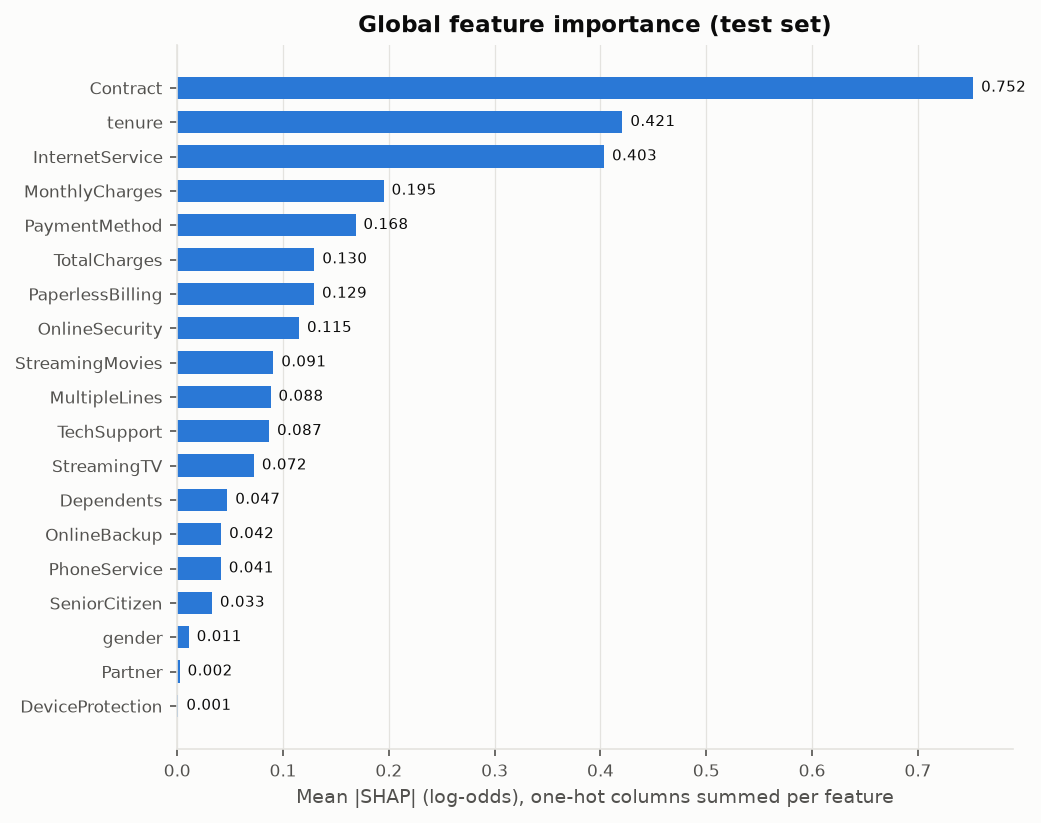

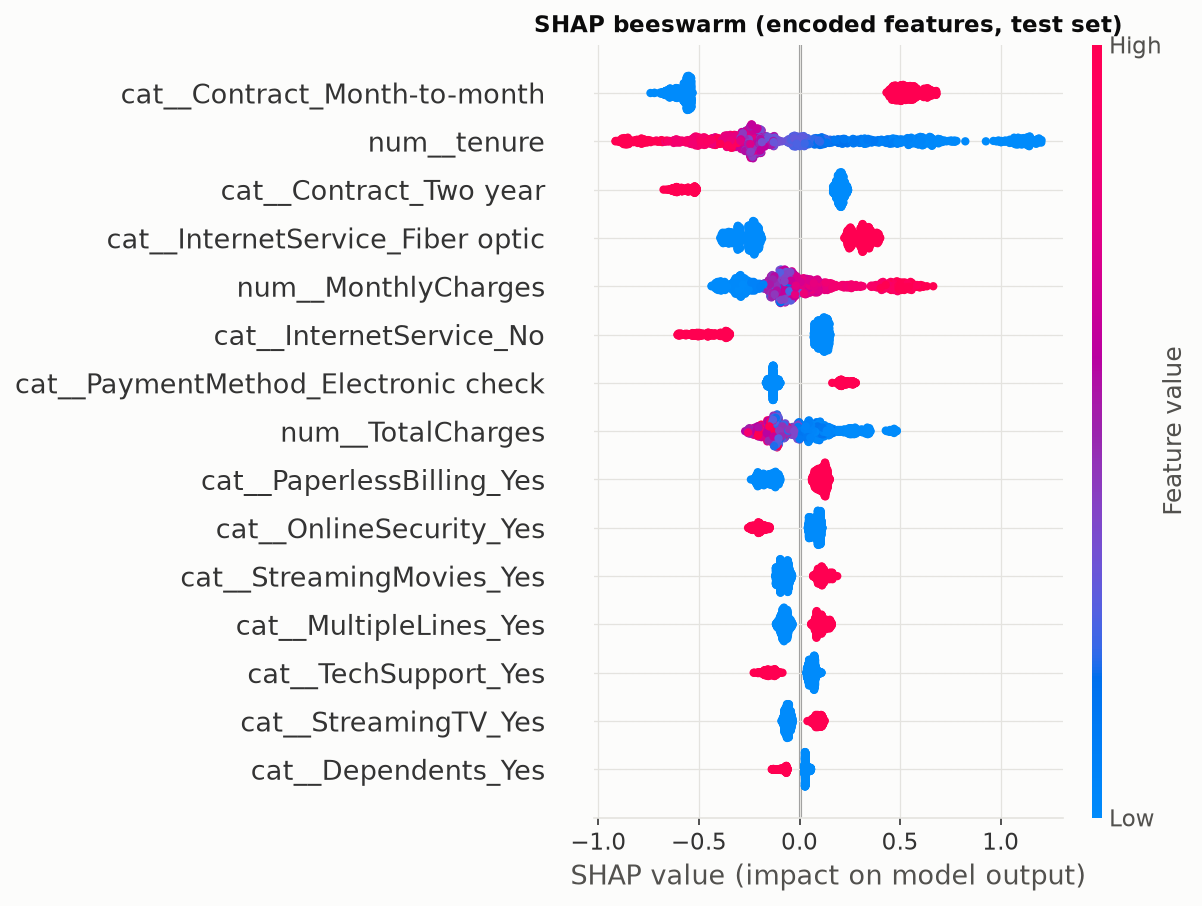

In [3]:
display(Image(FIGURES_DIR / "09_shap_global_bar.png", width=650))
display(Image(FIGURES_DIR / "10_shap_beeswarm.png", width=750))

**Cara membaca beeswarm:** setiap titik adalah satu pelanggan. Merah berarti nilai fitur tinggi (atau "Yes" untuk kolom one-hot), biru berarti rendah. Posisi horizontal menunjukkan arah dan besar pengaruhnya.

- **Contract** adalah fitur terkuat. Kontrak bulanan mendorong risiko naik, kontrak dua tahun mendorongnya turun paling kuat.
- **tenure** pendek (biru) menaikkan risiko, tenure panjang (merah) menurunkannya.
- **Fiber optic** menaikkan risiko; pelanggan tanpa internet berisiko rendah.
- **MonthlyCharges** tinggi menaikkan risiko.
- **Electronic check** dan **PaperlessBilling** menaikkan risiko; **OnlineSecurity** dan **TechSupport** menurunkannya.
- `gender`, `Partner`, dan `DeviceProtection` hampir tidak berpengaruh.

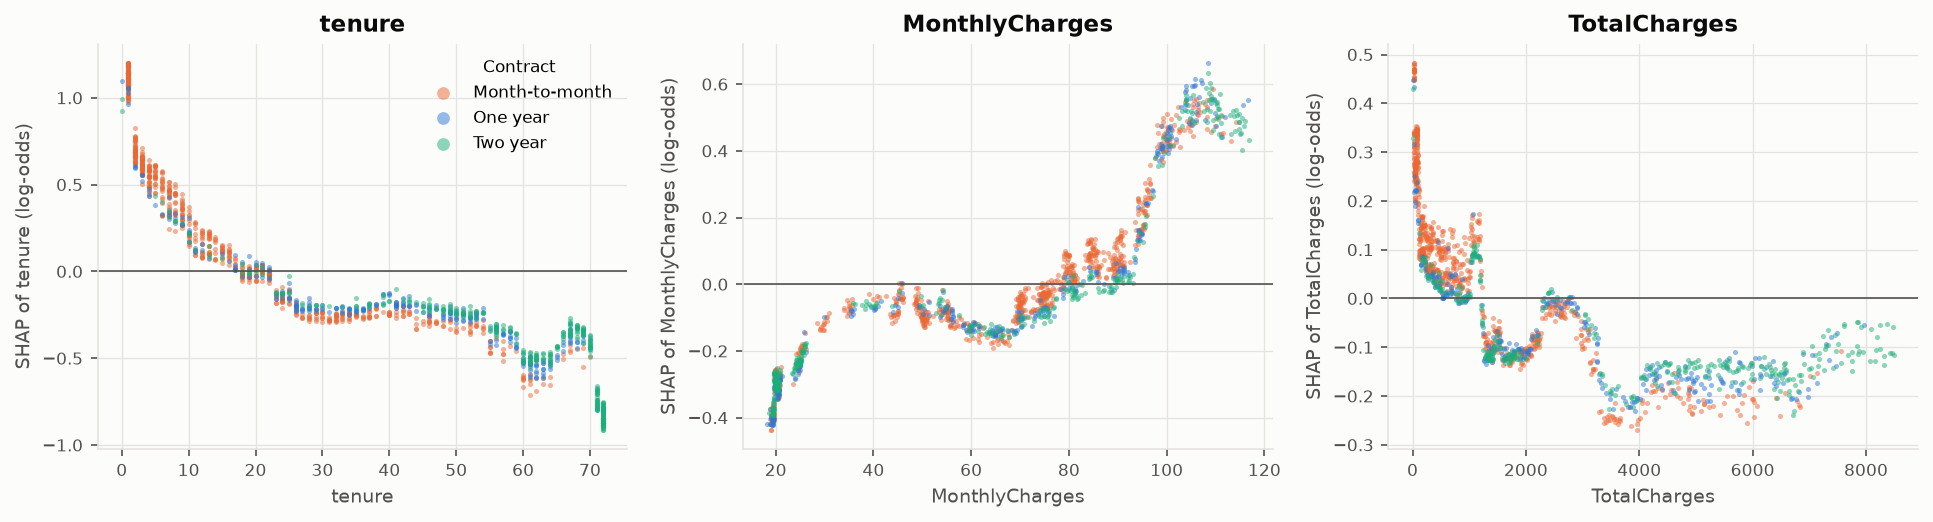

In [4]:
display(Image(FIGURES_DIR / "11_shap_dependence_numeric.png", width=950))

**Bentuk hubungan fitur numerik** (warna = jenis kontrak):

- **tenure:** kontribusinya turun tajam dari sekitar +1,0 di bulan pertama ke sekitar 0 di bulan ke-20, lalu terus negatif. Jadi tahun pertama adalah masa paling rawan.
- **MonthlyCharges:** kontribusinya paling negatif untuk tagihan sekitar 20 (umumnya tanpa internet), sedikit negatif di 40–70, mendekati 0 di sekitar 75–90, lalu naik tajam di atas sekitar 95. Bentuknya tidak linear; ini salah satu hal yang ditangkap LightGBM tetapi tidak oleh Logistic Regression biasa.
- **TotalCharges:** total kecil menaikkan risiko. Ini sebagian besar mencerminkan tenure pendek (keduanya berkorelasi kuat, lihat Fase 1).

## 2. Interpretasi lokal: tiga contoh pelanggan dari data test

In [5]:
examples = pick_examples(test, proba)
for label, idx in examples.items():
    print(f"{label}: customer {test.loc[idx, ID_COL]}, p(churn) = {proba[idx]:.2f}, actual = {'churn' if test.loc[idx, 'Churn'] else 'stay'}")
    display(explainer.explain_row(X_test.loc[[idx]]).round(3))

high_risk: customer 5178-LMXOP, p(churn) = 0.90, actual = churn


,feature,value,shap,direction
0,tenure,1,1.002,raises risk
1,Contract,Month-to-month,0.870,raises risk
2,InternetService,Fiber optic,0.446,raises risk
3,TotalCharges,95.1,0.294,raises risk
4,MonthlyCharges,95.1,0.217,raises risk


mid_risk: customer 9420-LOJKX, p(churn) = 0.50, actual = churn


,feature,value,shap,direction
0,Contract,Month-to-month,0.722,raises risk
1,InternetService,Fiber optic,0.469,raises risk
2,MonthlyCharges,99.1,0.414,raises risk
3,OnlineSecurity,Yes,-0.212,lowers risk
4,PaymentMethod,Credit card (automatic),-0.138,lowers risk


low_risk: customer 1166-PQLGG, p(churn) = 0.01, actual = stay


,feature,value,shap,direction
0,Contract,Two year,-1.076,lowers risk
1,tenure,72,-0.759,lowers risk
2,InternetService,No,-0.574,lowers risk
3,MonthlyCharges,19.55,-0.353,lowers risk
4,PaymentMethod,Bank transfer (automatic),-0.116,lowers risk


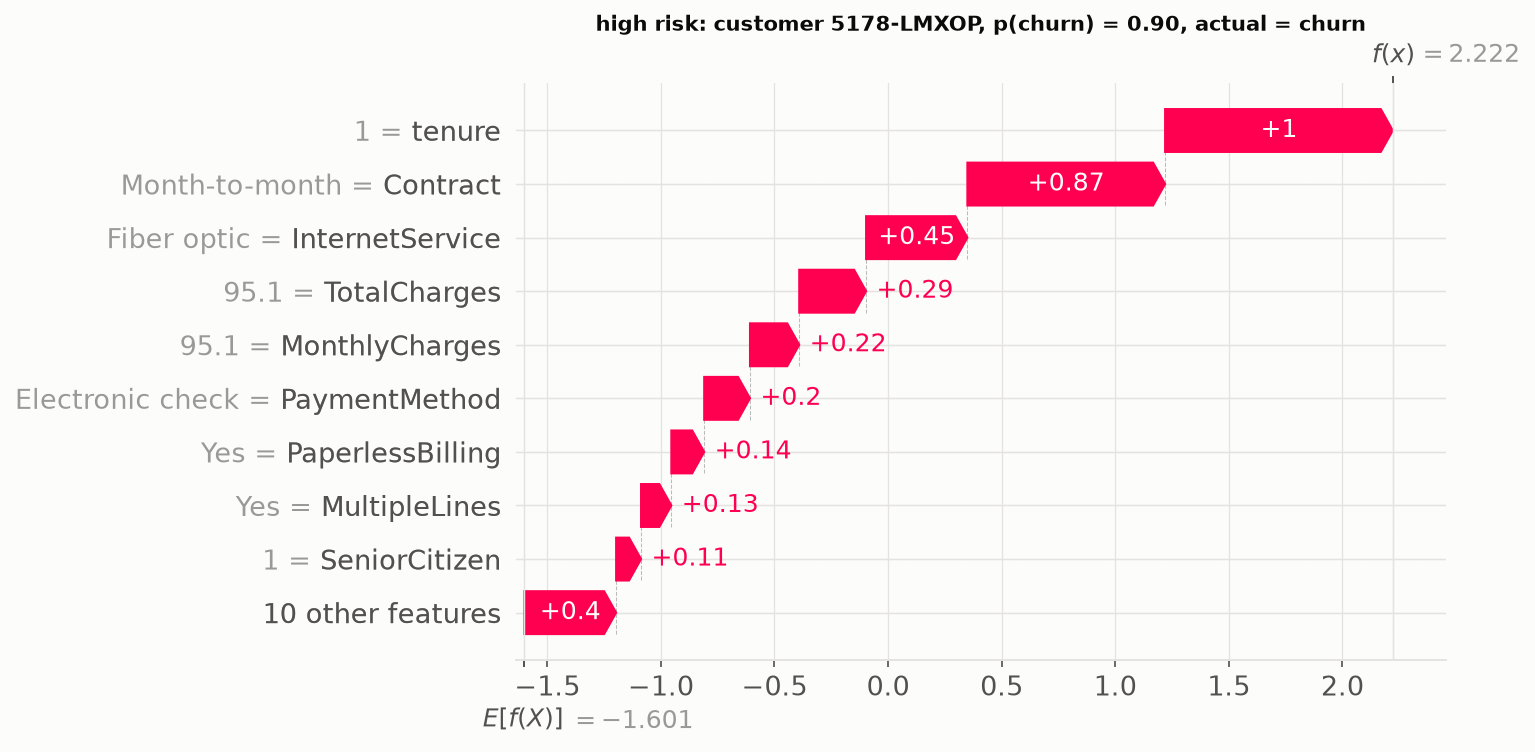

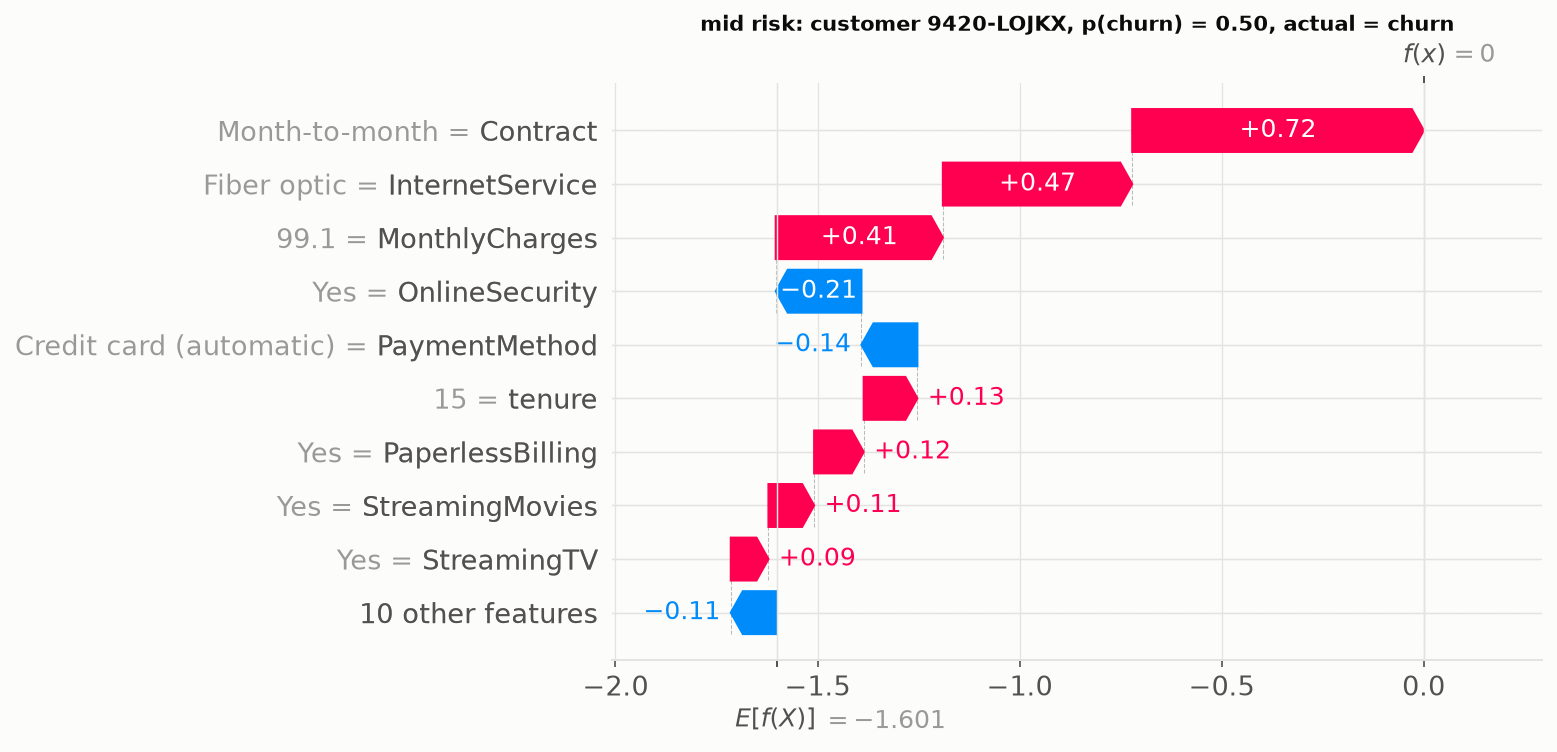

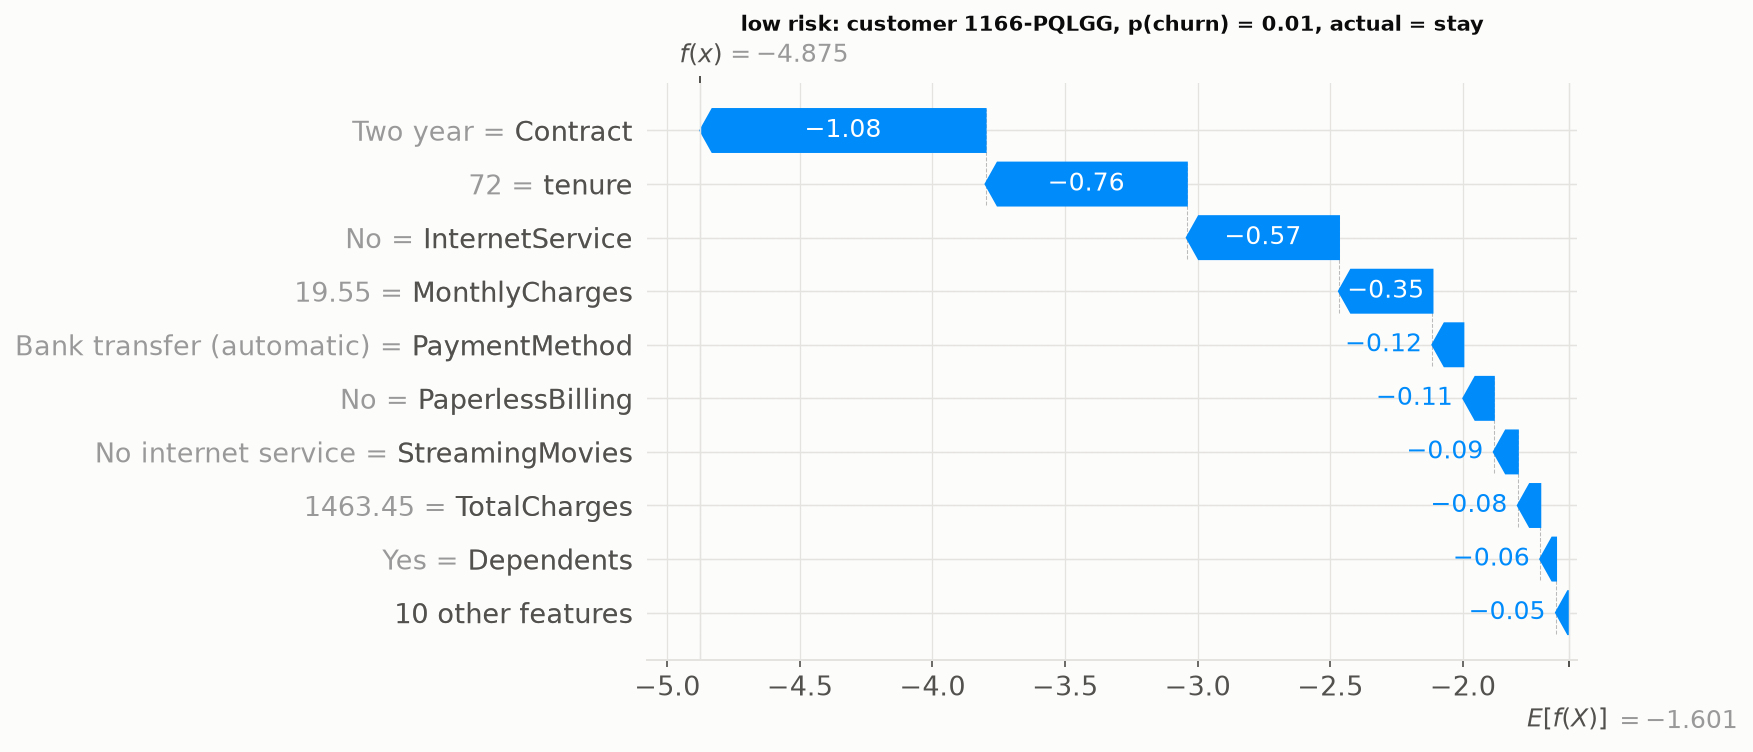

In [6]:
for f in sorted(FIGURES_DIR.glob("12*_shap_waterfall_*.png")):
    display(Image(f, width=750))

Waterfall dimulai dari nilai dasar model `E[f(X)]` (log-odds rata-rata), lalu setiap fitur menambah (merah) atau mengurangi (biru) sampai mencapai skor akhir pelanggan `f(x)`. Format penjelasan inilah yang dipakai aplikasi Streamlit di Fase 7: probabilitas churn plus faktor penyebab utamanya.

## 3. Statistik segmen pendukung rekomendasi (seluruh 7.043 pelanggan)

In [7]:
df = load_clean()
total_churners = df["Churn"].sum()

def seg(name, mask):
    s = df[mask]
    return {"segment": name, "n": len(s), "share_customers": len(s) / len(df),
            "churn_rate": s["Churn"].mean(), "share_of_all_churners": s["Churn"].sum() / total_churners}

m2m = df["Contract"] == "Month-to-month"
fiber = df["InternetService"] == "Fiber optic"
no_support = (df["TechSupport"] == "No") & (df["OnlineSecurity"] == "No")
pd.DataFrame([
    seg("all customers", df.index == df.index),
    seg("month-to-month & tenure <= 12", m2m & (df["tenure"] <= 12)),
    seg("month-to-month & tenure > 12", m2m & (df["tenure"] > 12)),
    seg("one/two-year contract", ~m2m),
    seg("fiber, no TechSupport & no OnlineSecurity", fiber & no_support),
    seg("fiber, with TechSupport or OnlineSecurity", fiber & ~no_support),
    seg("DSL", df["InternetService"] == "DSL"),
    seg("electronic check", df["PaymentMethod"] == "Electronic check"),
    seg("automatic payment", df["PaymentMethod"].str.contains("automatic")),
]).round(3)

,segment,n,share_customers,churn_rate,share_of_all_churners
0,all customers,7043,1.000,0.265,1.000
1,month-to-month & tenure <= 12,1994,0.283,0.514,0.548
2,month-to-month & tenure > 12,1881,0.267,0.335,0.338
3,one/two-year contract,3168,0.450,0.068,0.114
4,"fiber, no TechSupport & no OnlineSecurity",1765,0.251,0.550,0.520
5,"fiber, with TechSupport or OnlineSecurity",1331,0.189,0.245,0.174
6,DSL,2421,0.344,0.190,0.246
7,electronic check,2365,0.336,0.453,0.573
8,automatic payment,3066,0.435,0.160,0.262


Apakah risiko fiber hanya karena harganya lebih mahal? Bandingkan fiber dan DSL pada rentang tagihan yang sama:

In [8]:
band = pd.cut(df["MonthlyCharges"], [0, 50, 70, 90, 120])
df[df["InternetService"] != "No"].pivot_table(index=band, columns="InternetService", values="Churn",
                                               aggfunc=["mean", "size"], observed=True).round(3)

mean                size            
InternetService    DSL Fiber optic     DSL Fiber optic
MonthlyCharges                                        
(0, 50]          0.321         NaN   773.0         NaN
(50, 70]         0.163       0.625  1049.0       112.0
(70, 90]         0.071       0.509   552.0      1292.0
(90, 120]        0.021       0.336    47.0      1692.0

Apakah efek kontrak hanya karena pelanggan kontrak panjang sudah lama berlangganan? Bandingkan pada rentang tenure yang sama:

In [9]:
df.pivot_table(index="Contract", columns=pd.cut(df["tenure"], [-1, 12, 24, 48, 72]), values="Churn",
               aggfunc="mean", observed=True).round(3)

tenure,"(-1, 12]","(12, 24]","(24, 48]","(48, 72]"
Contract,,,,
Month-to-month,0.514,0.377,0.329,0.260
One year,0.105,0.081,0.106,0.129
Two year,0.000,0.000,0.022,0.033


## 4. Rekomendasi bisnis

Versi lengkap ada di `reports/business_recommendations.md`. Semua angka di bawah berasal dari sel-sel di atas.

1. **Onboarding 12 bulan pertama untuk pelanggan kontrak bulanan.** Segmen ini hanya 28,3% pelanggan tetapi menyumbang 54,8% dari seluruh churn (churn rate 51,4%).
2. **Tawarkan migrasi ke kontrak 1–2 tahun** kepada pelanggan bulanan yang skor risikonya tinggi. Pada tenure ≤ 12 bulan, churn kontrak bulanan 51,4% vs 1 tahun 10,5%. Hati-hati *selection bias*: pelanggan yang memilih kontrak panjang mungkin memang lebih loyal, jadi efeknya perlu diuji.
3. **Evaluasi pengalaman fiber optic dan bundel TechSupport/OnlineSecurity.** Pada tagihan 70–90, churn fiber 50,9% vs DSL 7,1%, jadi masalahnya bukan hanya harga. Pelanggan fiber tanpa kedua layanan dukungan churn 55,0%, sedangkan yang punya salah satunya 24,5%.
4. **Dorong pembayaran otomatis.** Churn electronic check 45,3% vs pembayaran otomatis 16,0%.
5. **Gunakan skor model dengan threshold berbasis biaya untuk memilih target kampanye, dan selalu sertakan grup kontrol.** Tingkat keberhasilan retensi 50% di `src/config.py` masih asumsi dan perlu diukur dari kampanye nyata.

**Keterbatasan:** semua pola di atas adalah korelasi pada data sintetis IBM (tagihan dalam USD) dan belum tentu berlaku untuk telco di Indonesia.